In [ ]:
#Cell 1 - Reading all files
import pandas as pd
from pathlib import Path

DATA = Path("C:/GameDev/LILA Task/player_data")


In [29]:
# Load all files (cleaned) - see Pipeline Checklist in Notion

frames, failed, skipped = [], [], []
seen = set()

# Every .nakama-0 file; sorted so February_10 comes before February_11
for f in sorted(DATA.rglob("*.nakama-0")):
    if f.name in seen:                         # same filename already loaded → duplicate copy
        skipped.append(f"{f.parent.name}/{f.name}")
        continue
    seen.add(f.name)
    try:
        one = pd.read_parquet(f)
        one["date"] = f.parent.name            # date from folder name
        frames.append(one)
    except Exception as e:
        failed.append((f.name, str(e)))

all_df = pd.concat(frames, ignore_index=True)

# Decode event from bytes to text
all_df["event"] = all_df["event"].apply(lambda v: v.decode("utf-8") if isinstance(v, bytes) else v)

# Drop impossible duplicate rows (logging bug): repeated Position/BotPosition and deaths.
# Loot/BotKill repeats are kept (mostly real multi-pickups / multi-kills).
cols = ["user_id", "match_id", "ts", "event", "x", "y", "z"]
DEATHS = ["Killed", "BotKilled", "KilledByStorm"]
drop = all_df.duplicated(subset=cols, keep="first") & all_df["event"].isin(["Position", "BotPosition"] + DEATHS)
all_df = all_df[~drop].reset_index(drop=True)

# Bot = file contains BotPosition (README's ID rule is wrong for 17 files)
all_df["is_bot"] = all_df.groupby(["user_id", "match_id"])["event"].transform(lambda s: (s == "BotPosition").any())

# Time: ts is labelled ms but is really Unix SECONDS
raw = all_df["ts"].astype("int64")
all_df["time_utc"] = pd.to_datetime(raw, unit="s")                     # real date/time (UTC)
all_df["t"] = raw - raw.groupby(all_df["match_id"]).transform("min")   # seconds since match start

# Summary
print("Files loaded:", len(frames), "| Failed:", len(failed), "| Skipped duplicates:", len(skipped))
print("Duplicate rows dropped:", drop.sum())
print("Total rows:", len(all_df), "| Matches:", all_df["match_id"].nunique())
print("Humans:", all_df.loc[~all_df["is_bot"], "user_id"].nunique(),
      "| Bots:", all_df.loc[all_df["is_bot"], "user_id"].nunique())

Files loaded: 1242 | Failed: 0 | Skipped duplicates: 1
Duplicate rows dropped: 149
Total rows: 88867 | Matches: 796
Humans: 248 | Bots: 92


In [ ]:
#Cell 2 - get humans and bots data from all files

# --- Humans vs bots ---

# Unique IDs where is_bot is False → humans
humans = all_df.loc[~all_df["is_bot"], "user_id"].nunique()

# Unique IDs where is_bot is True → bots
bots = all_df.loc[all_df["is_bot"], "user_id"].nunique()

print("Humans:", humans)
print("Bots:  ", bots)
print("Total: ", humans + bots)        # should equal 339

# --- Verify the is_bot rule ---
# Rows = event types, columns = is_bot (False = human, True = bot)
# If the rule is right, bots should only have bot events (e.g. BotPosition)
print(pd.crosstab(all_df["event"], all_df["is_bot"]))

Humans: 245
Bots:   94
Total:  339
is_bot         False  True 
event                      
BotKill         2232    183
BotKilled        403    297
BotPosition        0  21712
Kill               3      0
Killed             3      0
KilledByStorm     39      0
Loot           12770    115
Position       50711    636


In [11]:
# cell 4 - Record Kills/deaths by humans and bots

# --- Tag killer and victim for each combat event (human files) ---

# Fixed meanings from the README event table
KILLER_VICTIM = {
    "Kill":      ("human", "human"),
    "BotKill":   ("human", "bot"),
    "Killed":    ("human", "human"),
    "BotKilled": ("bot",   "human"),
}

def tag(row):
    # Storm deaths: victim is the file owner, human or bot
    if row["event"] == "KilledByStorm":
        return "storm", ("bot" if row["is_bot"] else "human")
    # Other combat events: look up the fixed meaning
    return KILLER_VICTIM.get(row["event"], (None, None))   # None for non-combat events

all_df[["killer", "victim"]] = all_df.apply(tag, axis=1, result_type="expand")

# Check the result
print(pd.crosstab(all_df["event"], [all_df["killer"], all_df["victim"]]))

killer          bot human       storm
victim        human   bot human human
event                                
BotKill           0  2415     0     0
BotKilled       700     0     0     0
Kill              0     0     3     0
Killed            0     0     3     0
KilledByStorm     0     0     0    39


In [ ]:
# Exploration: event combinations per file
#Used the README's ID rule (numeric = bot) on purpose. This revealed 17 numeric-ID
#files with no BotPosition, which led to classifying files by events instead.

#Findings # HOW?
#bot files dont have loot events; had position and loot so, its not a bot; also no botPosition registered. it matches with human files more

# Count each event type per file
per_file = pd.crosstab([all_df["user_id"], all_df["match_id"]], all_df["event"])

# Add a human/bot label per file
per_file["is_bot"] = per_file.index.get_level_values("user_id").astype(str).str.isdigit()

# 1. Max and average count of each event per file, human vs bot
print("MAX per file:")
print(per_file.groupby("is_bot").max().T)
print("\nAVERAGE per file:")
print(per_file.groupby("is_bot").mean().round(2).T)

# 2. Which combinations of events appear together in one file?
events = per_file.drop(columns="is_bot")
per_file["combo"] = events.apply(lambda r: " + ".join(sorted(r[r > 0].index)), axis=1)

print("\nHUMAN file combinations:")
print(per_file[~per_file["is_bot"]]["combo"].value_counts())

print("\nBOT file combinations:")
print(per_file[per_file["is_bot"]]["combo"].value_counts())

In [ ]:
# Exploration: To check whether bot kill event in human is registering bot's position instead of human's own
# --- Is the BotKill position the human's own position? ---

# HOW : we compared each kill’s own x/z with the nearest Position snapshot, and they were about 1.6 units apart.

key = ["user_id", "match_id"]
human = all_df[~all_df["is_bot"]]

# BotKill rows, and the human's own Position snapshots
bk  = human[human["event"] == "BotKill"][key + ["t", "x", "z"]].sort_values("t")
pos = human[human["event"] == "Position"][key + ["t", "x", "z"]].sort_values("t")

# For each BotKill, find the same human's nearest Position snapshot in time
near = pd.merge_asof(bk, pos, on="t", by=key, direction="nearest", suffixes=("_kill", "_pos"))

# Distance between kill position and the human's own position
near["dist"] = ((near["x_kill"] - near["x_pos"])**2 + (near["z_kill"] - near["z_pos"])**2) ** 0.5
near["dt"]   = (near["t"] - near.groupby(key)["t"].transform("min")).abs()   # just for reference

print("Distance from BotKill to the human's own nearest position (units):")
print(near["dist"].describe().round(2))
print("\nShare within 10 units:", round((near["dist"] <= 10).mean() * 100, 1), "%")

In [ ]:
# Exploration: To check the identical file found is actually duplicated or not
# ---------------------------------------------------------------
# A. Duplicate filename: same file in two folders? identical content?
# ---------------------------------------------------------------
# HOW : Check start session time and end session time on both files to check if any time mismatches; but both were identical
from collections import Counter

files = list(DATA.rglob("*.nakama-0"))
names = Counter(f.name for f in files)
dups = [n for n, c in names.items() if c > 1]          # filenames that appear more than once

for n in dups:
    paths = [f for f in files if f.name == n]          # all copies of this filename
    dfs = [pd.read_parquet(p) for p in paths]           # read each copy
    print("A. Duplicate:", n[:40], "...")

    for p, d in zip(paths, dfs):
        t = pd.to_datetime(d["ts"].astype("int64"), unit="s")   # real time (seconds)
        print("   folder:", p.parent.name, "| rows:", len(d),
              "| from", t.min(), "to", t.max())

    print("   Identical content:", dfs[0].equals(dfs[1]))

In [18]:
# Exploration: To check date mismatches, some rows have different data than their folder names.
# ---------------------------------------------------------------
# B. Date mismatches: why do some rows have a different date than their folder?
# ---------------------------------------------------------------

# Real date/time from ts (seconds, UTC)
real_dt = pd.to_datetime(all_df["ts"].astype("int64"), unit="s")

# Day number from the folder name, e.g. "February_10" → 10
folder_day = all_df["date"].str.split("_").str[1].astype(int)

# Rows where the real day differs from the folder day
mm = all_df[real_dt.dt.day != folder_day]
print("Mismatch rows:", len(mm), "| matches involved:", mm["match_id"].nunique())

# Which folder vs which real date
print(pd.crosstab(mm["date"], real_dt[mm.index].dt.date))

# What UTC hours these rows fall in
print("UTC hours:", sorted(real_dt[mm.index].dt.hour.unique()))

# Do these matches cross midnight? (start and end on different days)
span = all_df[all_df["match_id"].isin(mm["match_id"])].groupby("match_id")["ts"].agg(["min", "max"])
span = span.apply(lambda c: pd.to_datetime(c.astype("int64"), unit="s"))
print("Matches crossing midnight UTC:", (span["min"].dt.date != span["max"].dt.date).sum(), "of", len(span))

Mismatch rows: 436 | matches involved: 5
ts           2026-02-09  2026-02-10
date                               
February_10          14           0
February_11           0         422
UTC hours: [np.int32(23)]
Matches crossing midnight UTC: 3 of 5


In [ ]:
# Exploration: To check whether double deaths on same human is because of the duplicated file
# --- Human files with more than one death ---

DEATHS = ["Killed", "BotKilled", "KilledByStorm"]
key = ["user_id", "match_id"]

# Human files only (event-based is_bot)
human = all_df[~all_df["is_bot"]]

# Number of death events per file
death_count = human[human["event"].isin(DEATHS)].groupby(key).size()
multi = death_count[death_count > 1]
print("Human files with >1 death:", len(multi))

# For each such file: show every non-Position event in time order
for (uid, mid) in multi.index:
    f = human[(human["user_id"] == uid) & (human["match_id"] == mid)]
    print(f"\n{uid[:8]}... | rows: {len(f)} | last t: {f['t'].max()}")
    print(f[f["event"] != "Position"][["t", "event", "x", "z"]].sort_values("t").to_string(index=False))

In [ ]:
# EXPLORATION : to find exact duplicates and check whether it makes any sense with the gameplay, if not, remove duplication.
# for example, death events cannot be duplicated
# --- Exact duplicate rows, by event type ---
cols = ["user_id", "match_id", "t", "event", "x", "y", "z"]
dup = all_df[all_df.duplicated(subset=cols, keep="first")]
print("Exact duplicate rows by event:")
print(dup["event"].value_counts())
print("Files affected:", dup[["user_id", "match_id"]].drop_duplicates().shape[0])

Exact duplicate rows by event:
event
Loot         1234
Position      147
BotKill        34
BotKilled       2
Name: count, dtype: int64
Files affected: 450


In [ ]:
# EXPLORATION : Mapping Co-ordinates from game world to minimap and link them
# --- Coordinates: formula test, minimap sizes, bounds ---
# Conversion formula followed by readme
from PIL import Image          # pip install pillow, if missing

# Map settings from the README
MAPS = {
    "AmbroseValley": {"scale": 900,  "ox": -370, "oz": -473, "img": "AmbroseValley_Minimap.png"},
    "GrandRift":     {"scale": 581,  "ox": -290, "oz": -290, "img": "GrandRift_Minimap.png"},
    "Lockdown":      {"scale": 1000, "ox": -500, "oz": -500, "img": "Lockdown_Minimap.jpg"},
}

def to_pixel(x, z, map_id, size=1024):
    """World (x, z) → minimap pixel. y is elevation and not used."""
    m = MAPS[map_id]
    u = (x - m["ox"]) / m["scale"]          # 0..1 across the map
    v = (z - m["oz"]) / m["scale"]          # 0..1 up the map
    return u * size, (1 - v) * size         # flip: image row 0 is the top

# 1. README example → should be about (78, 890)
print("1. README example:", tuple(round(p) for p in to_pixel(-301.45, -355.55, "AmbroseValley")))

# 2. Real minimap sizes
print("\n2. Minimap sizes:")
for name, m in MAPS.items():
    w, h = Image.open(DATA / "minimaps" / m["img"]).size
    print(f"   {name:<14} {w} x {h}")

# 3. Share of points that land outside the 0..1024 image, per map
print("\n3. Points outside the map image:")
for name in MAPS:
    d = all_df[all_df["map_id"] == name]
    px, py = to_pixel(d["x"], d["z"], name)
    out = (px < 0) | (px > 1024) | (py < 0) | (py > 1024)
    print(f"   {name:<14} {out.sum():>5} of {len(d):>6}  ({out.mean()*100:.2f}%)")

1. README example: (78, 890)

2. Minimap sizes:
   AmbroseValley  4320 x 4320
   GrandRift      2160 x 2158
   Lockdown       9000 x 9000

3. Points outside the map image:
   AmbroseValley      0 of  60815  (0.00%)
   GrandRift          0 of   6853  (0.00%)
   Lockdown           0 of  21199  (0.00%)


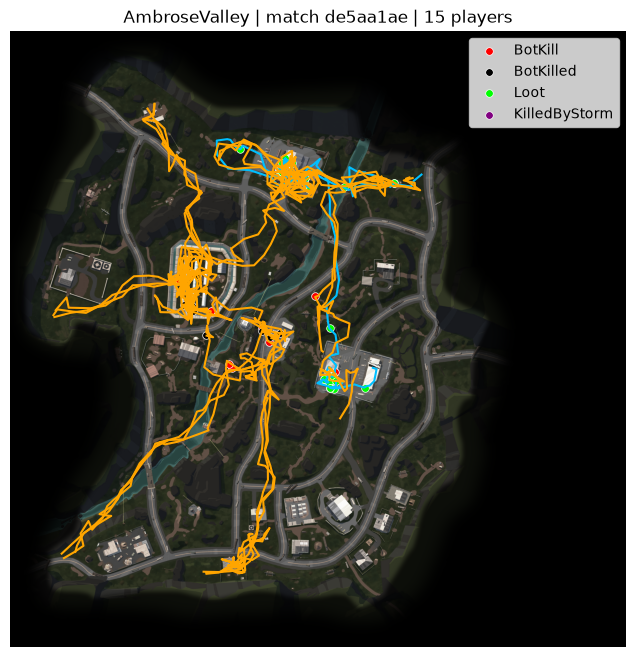

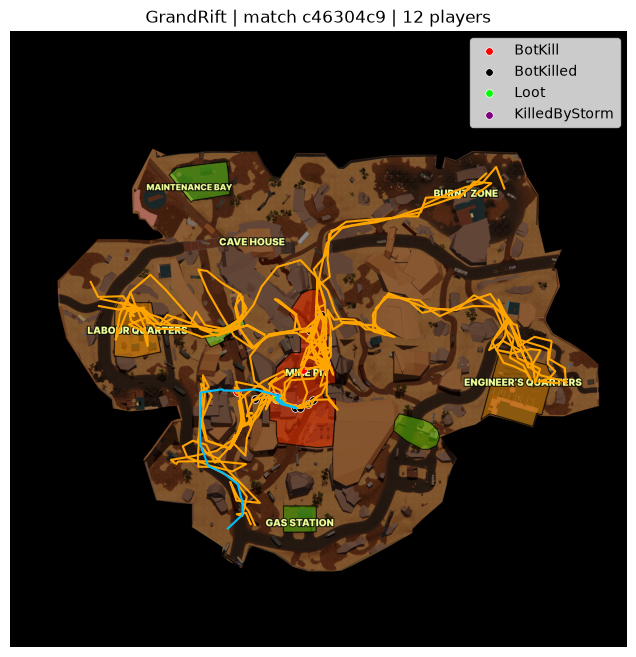

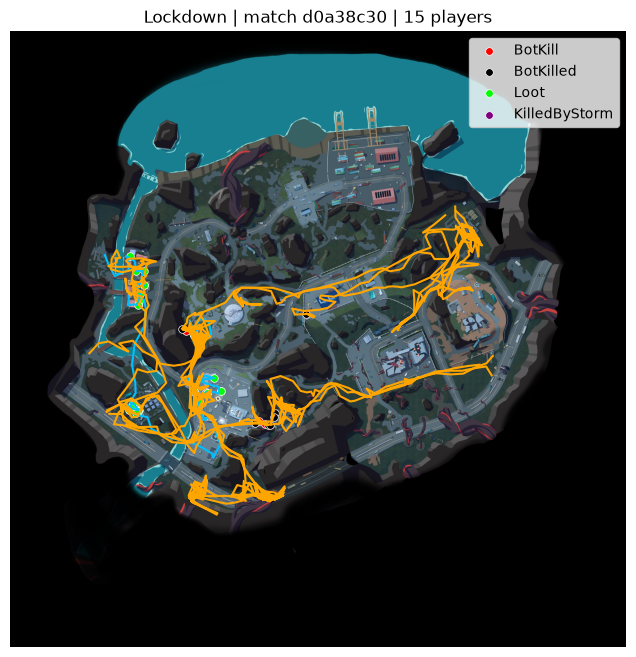

In [33]:
# Visual check: one match per map, drawn on its real minimap
# EXPLORATION : Draw visuals on the map to check if its working fine
import matplotlib.pyplot as plt

MARKERS = {"BotKill": "red", "BotKilled": "black", "Loot": "lime", "KilledByStorm": "purple"}

for name, cfg in MAPS.items():
    d = all_df[all_df["map_id"] == name]
    mid = d["match_id"].value_counts().index[0]          # busiest match on this map
    m = d[d["match_id"] == mid].sort_values("t")

    img = Image.open(DATA / "minimaps" / cfg["img"])
    W, H = img.size                                       # real image size

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(img)

    # Paths: humans blue, bots orange
    for (uid, bot), p in m.groupby(["user_id", "is_bot"]):
        mv = p[p["event"].isin(["Position", "BotPosition"])]
        u = (mv["x"] - cfg["ox"]) / cfg["scale"]
        v = (mv["z"] - cfg["oz"]) / cfg["scale"]
        ax.plot(u * W, (1 - v) * H, color="orange" if bot else "deepskyblue", lw=1.5)

    # Event markers
    for ev, color in MARKERS.items():
        e = m[m["event"] == ev]
        u = (e["x"] - cfg["ox"]) / cfg["scale"]
        v = (e["z"] - cfg["oz"]) / cfg["scale"]
        ax.scatter(u * W, (1 - v) * H, s=30, color=color, label=ev, edgecolors="white", linewidths=0.5)

    ax.set_title(f"{name} | match {mid[:8]} | {m['user_id'].nunique()} players")
    ax.legend(loc="upper right")
    ax.axis("off")
    plt.show()

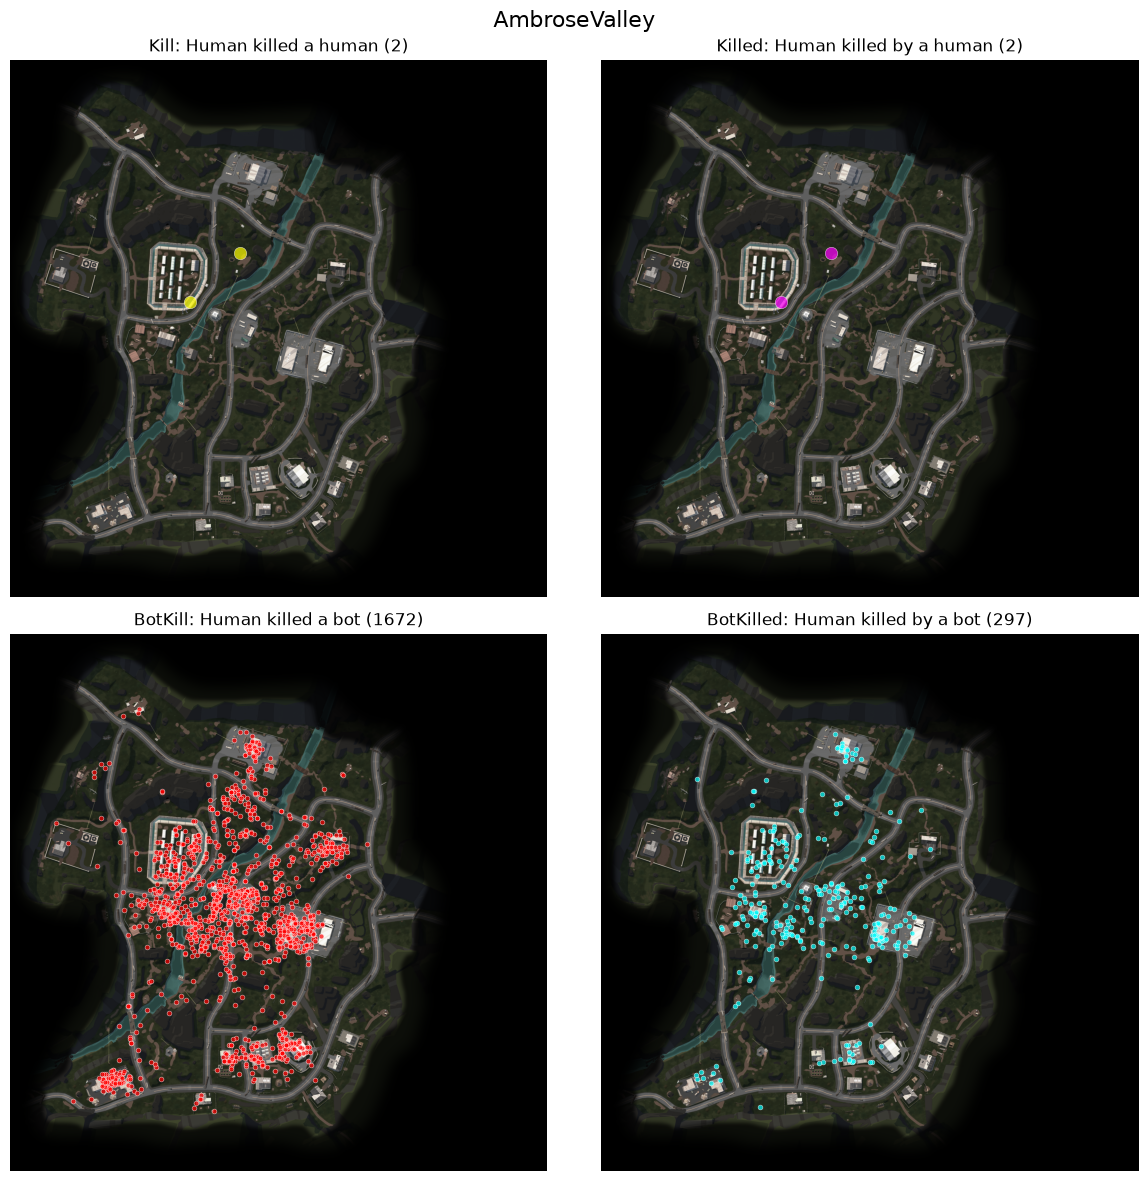

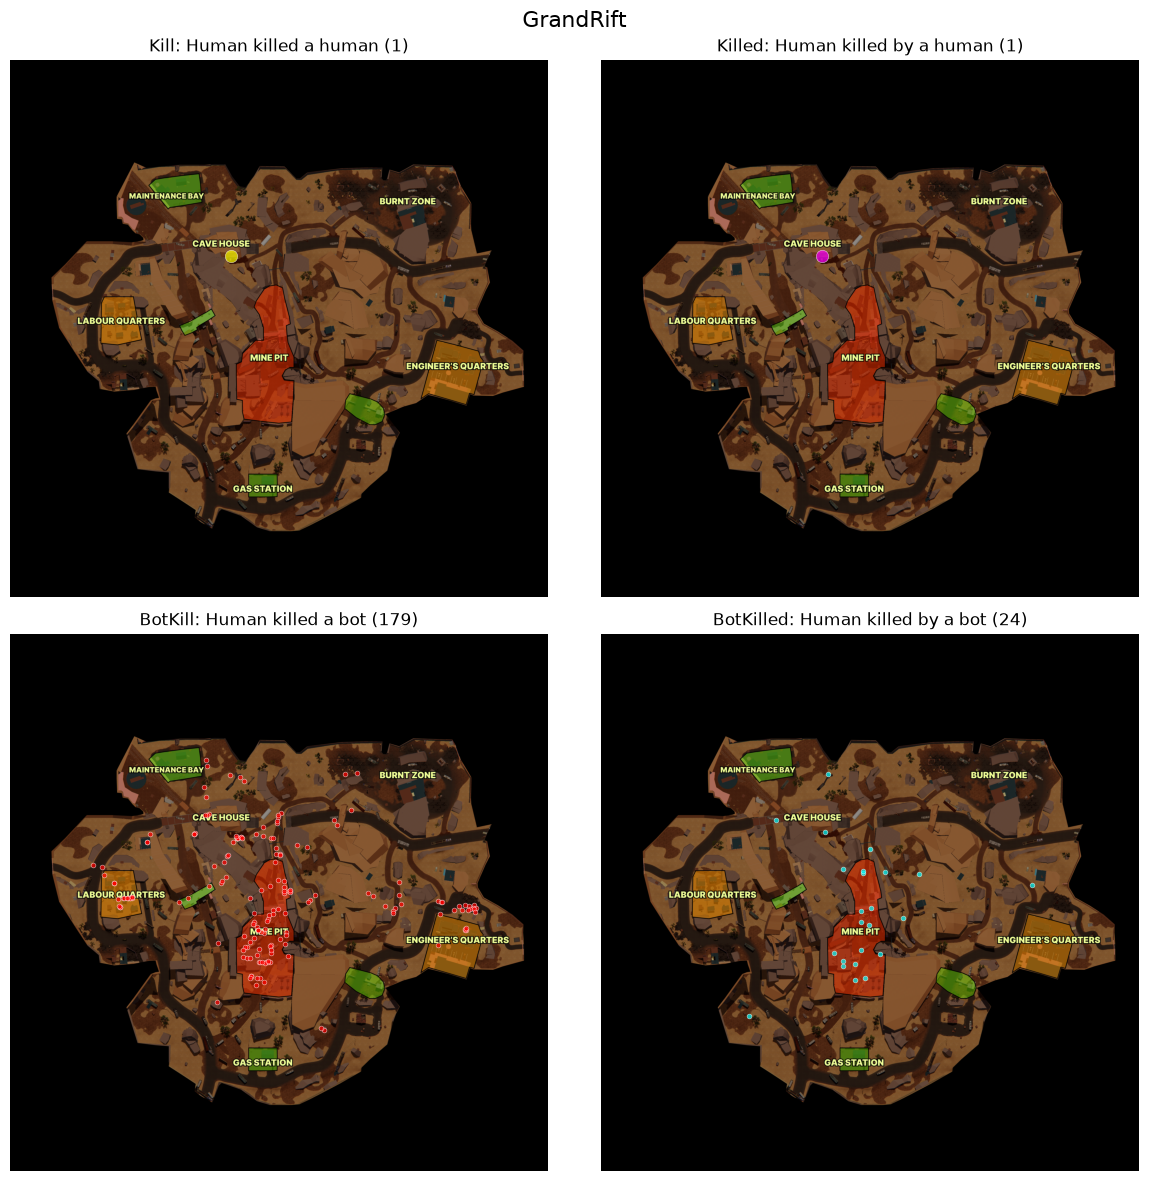

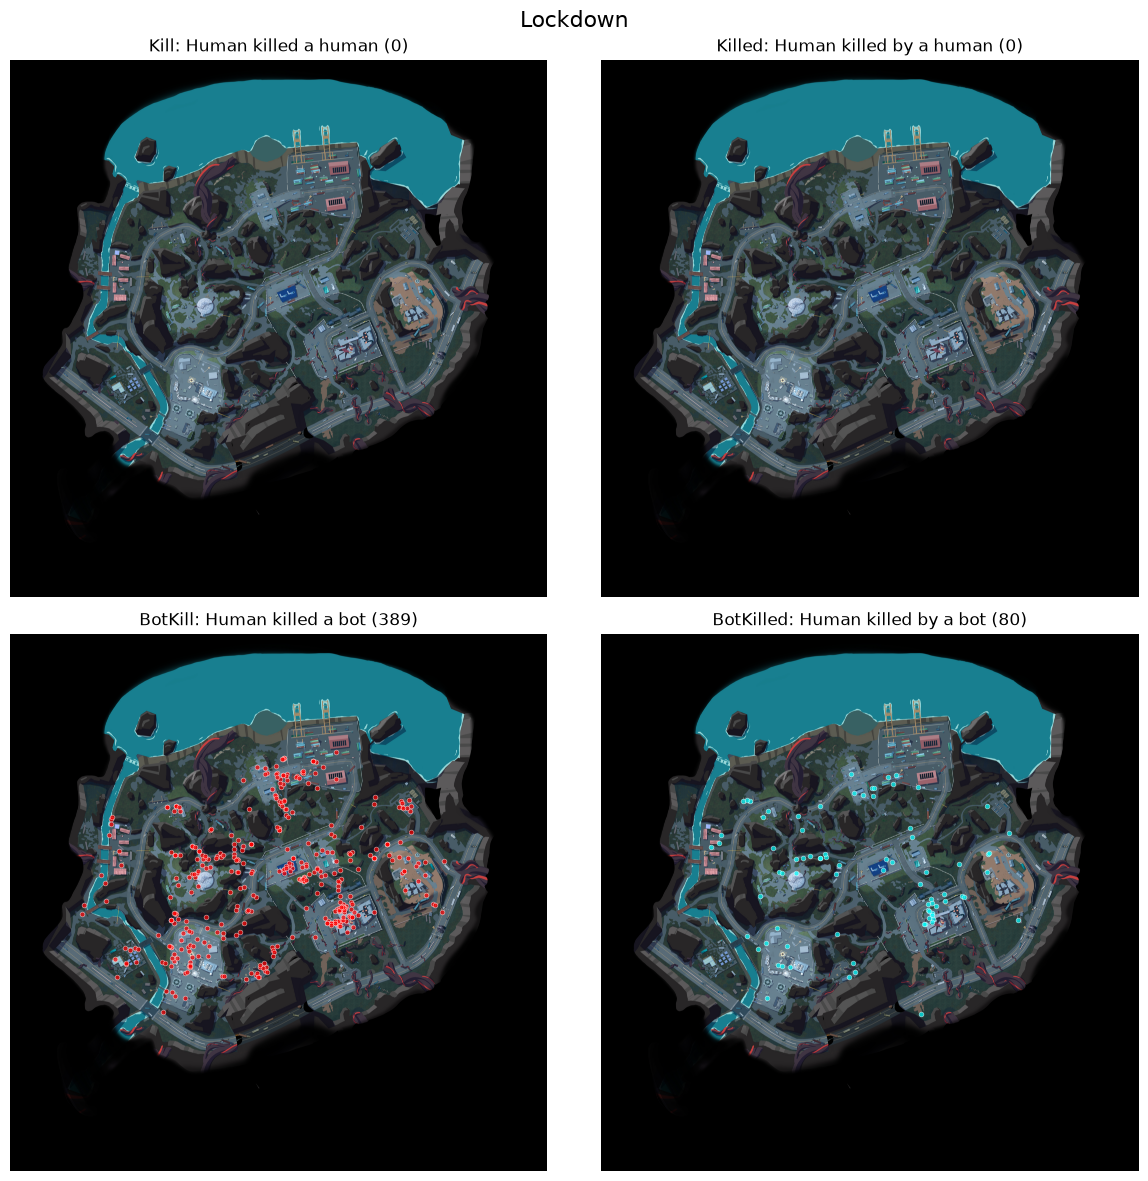

In [35]:
# Kill, Killed, BotKill, BotKilled — separate panels per map (human files only)
import matplotlib.pyplot as plt

EVENTS = {
    "Kill":      ("yellow",  "Human killed a human"),
    "Killed":    ("magenta", "Human killed by a human"),
    "BotKill":   ("red",     "Human killed a bot"),
    "BotKilled": ("cyan",    "Human killed by a bot"),
}

human = all_df[~all_df["is_bot"]]                       # combat comes from human files

for name, cfg in MAPS.items():
    img = Image.open(DATA / "minimaps" / cfg["img"])
    W, H = img.size                                     # real image size
    d = human[human["map_id"] == name]

    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    for ax, (ev, (color, meaning)) in zip(axes.flat, EVENTS.items()):
        e = d[d["event"] == ev]
        u = (e["x"] - cfg["ox"]) / cfg["scale"]         # fraction across
        v = (e["z"] - cfg["oz"]) / cfg["scale"]         # fraction up
        ax.imshow(img)
        ax.scatter(u * W, (1 - v) * H,
                   s=80 if len(e) < 20 else 12,          # rare events drawn bigger
                   color=color, alpha=0.7, edgecolors="white", linewidths=0.4)
        ax.set_title(f"{ev}: {meaning} ({len(e)})")
        ax.axis("off")

    fig.suptitle(name, fontsize=16)
    plt.tight_layout()
    plt.show()

In [36]:
# Humans and bots per match
per_match = all_df.groupby("match_id").agg(
    map=("map_id", "first"),
    humans=("user_id", lambda s: s[~all_df.loc[s.index, "is_bot"]].nunique()),
    bots=("user_id",   lambda s: s[all_df.loc[s.index, "is_bot"]].nunique()),
)

# How many matches had 0, 1, 2, 3... humans
print("Matches by number of humans:")
print(per_match["humans"].value_counts().sort_index())

# How many matches had 0, 1, 2, 3... bots
print("\nMatches by number of bots:")
print(per_match["bots"].value_counts().sort_index())

# The busiest matches
print("\nTop 10 matches by humans:")
print(per_match.sort_values("humans", ascending=False).head(10))

Matches by number of humans:
humans
1    794
2      2
Name: count, dtype: int64

Matches by number of bots:
bots
0     744
4       2
6      24
7       8
11      4
13      4
14     10
Name: count, dtype: int64

Top 10 matches by humans:
                                                         map  humans  bots
match_id                                                                  
a71c3aa8-8a2c-4efb-9859-98129368b9bb.nakama-0  AmbroseValley       2     0
fbbc5d02-dd79-42fb-bba5-d768023891c8.nakama-0  AmbroseValley       2    14
01464ac0-5b9c-47f2-b12a-50d5948a4ac2.nakama-0  AmbroseValley       1     0
015365c2-45fe-4ab2-851e-ac3a2b506578.nakama-0  AmbroseValley       1     0
016339a3-35af-4d81-b49c-bc8371ac2b30.nakama-0  AmbroseValley       1     0
01640e35-52ed-4f7a-8887-3ddb09def505.nakama-0  AmbroseValley       1     0
018ce847-fe23-405e-a6c0-48ba53766681.nakama-0  AmbroseValley       1     0
019dbb49-20ac-465f-8c16-7de72a0592fd.nakama-0  AmbroseValley       1     0
01d30b66-f767-